In [14]:
# we first import packages and libraries needed
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from collections import defaultdict
from tqdm import tqdm


# We set a global configuration for matplotlib to obtain well-readable plots
SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# fixing random generator for reproducibility
rng = np.random.default_rng(0)

In [15]:
airfield_stats_test = pd.read_csv('airfield_statistics_test.csv')
airfield_stats_train = pd.read_csv('airfield_statistics_train.csv')

X_train_origin = airfield_stats_train.iloc[:, :6].values  
y_train_origin = airfield_stats_train.iloc[:, 6].values

X_train = X_train_origin.copy()
y_train = y_train_origin.copy()

X_test_origin = airfield_stats_test.iloc[:, :6].values  
y_test_origin = airfield_stats_test.iloc[:, 6].values  

X_test = X_test_origin.copy()
y_test = y_test_origin.copy()

cat_columns_dict = {i: False for i in range(X_train.shape[1])} 

feature_names = airfield_stats_train.columns[:6].tolist()  


In [16]:
def dense(X, W, b):
    """Full-connected MLP layer.

    Parameters:
        X (np.ndarray): K x h_in array of inputs, where K is the batch size and h_in is the input dimension.
        W (np.ndarray): h_out x h_in array for weights matrix parameters, where h_out is the output dimension.
        b (np.ndarray): Length h_out 1-D array for bias parameters

    Returns:
        a (np.ndarray): K x h_out array of pre-activations
    """
    a = np.vstack([W @ x + b for x in X]) ## <-- SOLUTION
    return a

In [17]:
## EDIT THIS FUNCTION
def relu_activation(a):
    """ReLU activation function.

    Parameters:
        a: K x h_out array of pre-activations

    Returns:
        h: K x h_out array of post-activations
    """
    # compute post-activations
    h = np.maximum(a, 0.)  ## <-- SOLUTION
    return h

## EDIT THIS FUNCTION
def grad_relu_activation(a):
    """Gradient of ReLU activation function.

    Parameters:
        a: K x h_out array of pre-activations

    Returns:
        grad: K x h_out gradient array of post-activations
    """
    # compute gradient
    grad = np.zeros_like(a) ## <-- SOLUTION
    grad[a>0] = 1 ## <-- SOLUTION
    return grad

In [18]:
import numpy as np


def random_boolean_array(n, m):

    arr = np.array([False] * n + [True] * (m - n)) 
    np.random.shuffle(arr)
    return arr


n, m = 5, 10
random_array = random_boolean_array(n, m)
print(random_array)

[False  True False  True  True False False  True False  True]


In [19]:
# A lookup table for activation functions by their names.
activation_table = {
    "relu": relu_activation,
    "identity": lambda x: x
}

# A lookup table for gradient of activation functions by their names.
grad_activation_table = {
    "relu": grad_relu_activation,
    "identity": lambda x: np.ones_like(x)
}

class MLP:
    """
    This class represents a Multi-Layer Perceptron (MLP), that we are going
    to use to encapsulate two components:
        1. layers: the sequence of layers, where each layer is stored in
            a dictionary in the format {"W": np.ndarray, "b": np.ndarray},
            where "W" points to the weights array, and "b" points to
            the bias vector.
        2. rng: a pseudo random number generator (RNG) initialised to generate
            the random weights in a reproducible manner between different
            runtime sessions.
    This class is also shipped with methods that perform essential operations
    with a MLP, including:
        - add_layers: which creates a new layer with specified dimensions.
        - predict: applies the MLP forward pass to make predictions and produces
            a computational graph for the forward pass that can be used to
            compute gradients using backpropagation algorithm.
        in addition to other light functions that return simple statistics about
        the MLP.
    """
    def __init__(self, seed=42):
        self.layers = []
        self.rng = np.random.default_rng(seed)

    def n_parameters(self):
        """Return the total number of parameters of weights and biases."""
        return sum(l["b"].size + l["W"].size for l in self.layers)

    def n_layers(self):
        """Return current number of MLP layers (including input and output)."""
        return len(self.layers) + 1 if len(self.layers) > 0 else 0

    def layer_dim(self, index):
        """Retrieve the dimensions of the MLP layer at `index`."""
        return self.layers[index]["W"].shape

    def add_layer(self, in_dim, out_dim, activation="identity"):
        """Add fully connected layer to MLP.

        Parameters:
            in_dim (int): The input dimension of the layer.
            out_dim (int): The output dimension of the layer.
            activation (str): The activation function name.
        """
        # check if input-dimension matches output-dimension of previous layer
        if self.n_layers() > 0:
            last_out_dim, _ = self.layer_dim(-1)
            assert in_dim == last_out_dim, f"Input-dimension {in_dim} does not match output-dimension {last_out_dim} of previous layer."

        # the first layer, in our convention illustrated, does not apply activation on the input features X.
        if self.n_layers() == 0:
            assert activation == "identity", "Should not apply activations on the input features X, use Identity function for the first layer."

        # store each layer as a dictionary in the list, as shown in the
        # attached diagram.
        self.layers.append({
            # only for debugging.
            "index": len(self.layers),
            # apply Glorot initialisation for weights.
            # hint: use self.rng.normal()
            "W": self.rng.normal(size=(out_dim, in_dim)) * np.sqrt(2. / (in_dim + out_dim)), ## <-- SOLUTION
            # initialise bias vector with zeros.
            "b": np.zeros(out_dim), ## <-- SOLUTION
            # store the activation function (as string)
            "activation": activation
        })

    def add_layer_dropout(self, in_dim, out_dim, dropout_value, activation="identity"):
        """Add fully connected layer to MLP.

        Parameters:
            in_dim (int): The input dimension of the layer.
            out_dim (int): The output dimension of the layer.
            activation (str): The activation function name.
        """
        # check if input-dimension matches output-dimension of previous layer
        if self.n_layers() > 0:
            last_out_dim, _ = self.layer_dim(-1)
            assert (
                in_dim == last_out_dim
            ), f"Input-dimension {in_dim} does not match output-dimension {last_out_dim} of previous layer."

        real_layer = random_boolean_array(int(in_dim*(1-dropout_value)), in_dim)
        
        W_origin = self.rng.normal(size=(out_dim, in_dim))* np.sqrt(2.0 / (in_dim + out_dim))
        for i in range(out_dim):
            W_origin[i, :] = W_origin[i,:]*real_layer
                                          


        # the first layer, in our convention illustrated, does not apply activation on the input features X.
        if self.n_layers() == 0:
            assert (
                activation == "identity"
            ), "Should not apply activations on the input features X, use Identity function for the first layer."

        # store each layer as a dictionary in the list, as shown in the
        # attached diagram.
        self.layers.append(
            {
                # only for debugging.
                "index": len(self.layers),
                # apply Glorot initialisation for weights.
                # hint: use self.rng.normal()
                "W": W_origin,  ## <-- SOLUTION
                # initialise bias vector with zeros.
                "b": np.zeros(out_dim),  ## <-- SOLUTION
                # store the activation function (as string)
                "activation": activation,
            }
        )

    def predict(self, X):
        """Apply the forward pass on the input X and produce prediction and the
        forward computation graph.

        Parameters:
            X (np.ndarray): Feature matrix.

        Returns:
            (np.ndarray, List[Dict[str, np.ndarray]]): A tuple of the
            predictions and the computation graph as a sequence of intermediate
            values through the MLP, specifically each layer will have a corresponding
            intermediate values {"a": np.ndarray, "h": np.ndarray}, as shown in the
            attached diagram above.
        """
        # We assume that we work with a batch of examples (ndim==2).
        if X.ndim == 1:
            # If one example passed, add a dummy dimension for the batch.
            X = X.reshape(1, -1)

        # store pre- and post-activations in list
        forward_pass = [{"index": 0, "a": X, "h": X}]

        # iterate through hidden layers
        for k in range(1, len(self.layers)):
            # compute pre-activations
            a = dense(forward_pass[k - 1]["h"], self.layers[k - 1]["W"], self.layers[k - 1]["b"]) ## <-- SOLUTION
            activation = activation_table[self.layers[k]["activation"]] ## <-- SOLUTION
            forward_pass.append({"index": k, "a" : a, "h" : activation(a)})

        y_hat = dense(forward_pass[-1]["h"], self.layers[-1]["W"], self.layers[-1]["b"]) ## <-- SOLUTION
        # predicted target is output of last layer
        return y_hat, forward_pass

In [20]:
def mse_loss(y_true, y_pred):
    """Compute MSE-loss

    Parameters:
        y_true: ground-truth array, with shape (K, )
        y_pred: predictions array, with shape (K, )

    Returns:
        loss (float): MSE-loss
    """
    assert y_true.size == y_pred.size, "Ground-truth and predictions have different dimensions."

    # Adjustment to avoid subtraction between (K,) and (1, K) arrays.
    y_true = y_true.reshape(y_pred.shape)

    # Compute MSE loss
    loss = np.mean((y_true - y_pred)**2, keepdims=True) ## <-- SOLUTION
    return loss

In [21]:
def compound_loss(T, T_pred, l=0):

    assert T.size == T_pred.size, "Error"

    T = T.reshape(T_pred.shape)

    T_min, T_max = T[:,0], T[:,1]
    T_min_pred, T_max_pred = T_pred[:,0], T_pred[:,1]

    T_min = T_min.reshape(T_min_pred.shape)
    T_max = T_max.reshape(T_max_pred.shape)

    MSE_min = mse_loss(T_min, T_min_pred)
    MSE_max = mse_loss(T_max, T_max_pred)

    key = [T_min_pred > T_max_pred]

    return MSE_min + MSE_max + l*np.mean(key)


def compound_grad(T, T_pred, l=0):
    assert T.shape == T_pred.shape, "Error: Shapes of T and T_pred must match!"

    T_min, T_max = T[:, 0], T[:, 1]
    T_min_pred, T_max_pred = T_pred[:, 0], T_pred[:, 1]

    N = T_min.size

    grad_min = (2.0 * (-T_min + T_min_pred) / N).reshape(-1, 1)
    grad_max = (2.0 * (-T_max + T_max_pred) / N).reshape(-1, 1)

    key = (T_min_pred > T_max_pred).astype(float).reshape(-1, 1)

    grad_min += (l * key) / N
    grad_max -= (l * key) / N

    return np.hstack((grad_min, grad_max))

In [22]:
def backpropagate(layers, forward_pass, delta_output):
    """
    Apply the backpropagation algorithm to the MLP layers to compute the gradients starting from
    the output layer to the input layer, and starting the chain rule from the
    partial derivative of the loss function w.r.t the predictions $\hat{y}$

    Parameters:
        layers (List[Dict[str, np.ndarray]]): The MLP sequence of layers, as shown in the diagrams.
        forward_pass (List[Dict[str, np.ndarray]]): The forward pass intermediate values for
            each layer, representing a computation graph.
        delta_output (np.ndarray): the partial derivative of the loss function w.r.t the
            predictions $\hat{y}$, has the shape (K, 1), where K is the batch size.
    Returns:
        gradients (List[Dict[str, np.ndarray]]): The computed gradient using a structure symmetric in the layers, as shown
            in the diagrams.

    """
    # Create a list that will contain the gradients of all the layers.
    gradients = []

    # Initialise delta.
    delta = delta_output

    assert len(layers) == len(forward_pass), "Number of layers is expected to match the number of forward pass layers"

    # Iterate on layers backwardly, from output to input.
    # Calculate gradients w.r.t. weights and biases of each level and store in list of dictionaries.
    for layer, forward_computes in reversed(list(zip(layers, forward_pass))):   # zip iterates through pairs of layers and forward_pass
        assert forward_computes["index"] == layer["index"], "Mismatch in the index."

        h = forward_computes["h"]
        assert delta.shape[0] == h.shape[0], "Mismatch in the batch dimension."

        # Gradients are average gradients over batch
        gradients.append({"W" : (delta.T @ h) / h.shape[0], # <-- SOLUTION
                          "b" : delta.mean(axis=0)}) # <-- SOLUTION

        # Update the delta for the next iteration
        grad_activation_f = grad_activation_table[layer["activation"]]
        grad_activation = grad_activation_f(forward_computes["a"])

        # Calculate the delta for the backward layer.
        delta = np.stack([np.diag(gi) @ layer["W"].T @ di
                           for (gi, di) in zip(grad_activation, delta)]) # <-- SOLUTION.


    # Return now ordered list matching the layers.
    gradients = list(reversed(gradients))
    return gradients

<>:2: SyntaxWarning: invalid escape sequence '\h'
<>:2: SyntaxWarning: invalid escape sequence '\h'
C:\Users\User\AppData\Local\Temp\ipykernel_5244\3984133441.py:2: SyntaxWarning: invalid escape sequence '\h'
  """


In [23]:
def sgd_step(X, y, mlp, lam=0, learning_rate = 1e-3):
    """
    Apply a stochastic gradient descent step using the sampled batch.
    Parameters:
        X (np.ndarray): The input features array batch, with dimension (K, p).
        y (np.ndarray): The ground-truth of the batch, with dimension (K, 1).
        learning_rate (float): The learning rate multiplier for the update steps in SGD.
    Returns:
        updated_layers (List[Dict[str, np.ndarray]]): The updated layers after applying SGD.
    """
    # Compute the forward pass.
    y_hat, forward_pass = mlp.predict(X) ## <-- SOLUTION.

    # Compute the partial derivative of the loss w.r.t. to predictions `y_hat`.
    delta_output = compound_grad(y, y_hat, lam) ## <-- SOLUTION

    # Apply backpropagation algorithm to compute the gradients of the MLP parameters.
    gradients = backpropagate(mlp.layers, forward_pass, delta_output)  ## <-- SOLUTION.

    # mlp.layers and gradients are symmetric, as shown in the figure.
    updated_layers = []
    for layer, grad in zip(mlp.layers, gradients):
        W = layer["W"] - learning_rate * grad["W"] ## <-- SOLUTION.
        b = layer["b"] - learning_rate * grad["b"] ## <-- SOLUTION.
        updated_layers.append({"W": W, "b": b,
                               # keep the activation function.
                               "activation": layer["activation"],
                               # We use the index for asserts and debugging purposes only.
                               "index": layer["index"]})
    return updated_layers

def r2_score(y, y_hat):
    """R^2 score to assess regression performance."""

    # Adjustment to avoid subtraction between (K,) and (1, K) arrays.
    y = y.reshape(y_hat.shape)
    y_bar = y.mean()

    ss_tot = ((y - y_bar)**2).sum()
    ss_res = ((y - y_hat)**2).sum()
    return 1 - (ss_res/ss_tot)

def sgd(X_train, y_train, X_test, y_test, mlp, lam=0, learning_rate = 1e-3,
        n_epochs=10, minibatchsize=1, seed=42):
    """
    Run the Stochastic Gradient Descent (SGD) algorithm to optimise the parameters of MLP model to fit it on
    the training data using MSE loss.

    Parameters:
        X_train (np.ndarray): The training data features, with shape (N^{training}, p).
        y_train (np.ndarray): The training data ground-truth, with shape (N^{training}, 1).
        X_test (np.ndarray): The testing data features, with shape (N^{test}, p).
        y_test (np.ndarray): The testing data ground-truth, with shape (N^{test}, 1).
        mlp (MLP): The MLP object enacpsulating the MLP model.
        learning_rate (float): The learning_rate multiplier used in updating the parameters at each iteration.
        n_epochs (int): The number of training cycles that each covers the entire training examples.
        minibatchsize (int): The batch size used in each SGD step.
        seed (int): A seed for the RNG to ensure reproducibility across runtime sessions.

    Returns:
        mlp (MLP): MLP object encapuslating the trained MLP model.
        losses_train (np.ndarray): Train losses over epochs.
        losses_tset (np.ndarray): Test losses over epochs.
    """

    # get random number generator
    rng = np.random.default_rng(seed)

    # compute number of iterations per epoch
    n_iterations = int(len(y_train) / minibatchsize)

    # store losses
    losses_train = []
    losses_test = []

    epochs_bar = tqdm(range(n_epochs), desc="Epochs")

    for i in epochs_bar:

        # shuffle data
        p = rng.permutation(len(y_train))
        X_train_shuffled = X_train[p]
        y_train_shuffled = y_train[p]

        for j in range(n_iterations):
            # get batch
            X_batch = X_train_shuffled[j*minibatchsize : (j+1)*minibatchsize]
            y_batch = y_train_shuffled[j*minibatchsize : (j+1)*minibatchsize]

            # apply sgd step
            updated_layers = sgd_step(X_batch, y_batch, mlp, lam, learning_rate) ## <-- SOLUTION.

            # update weights and biases of MLP
            mlp.layers = updated_layers ## <-- SOLUTION.

        # compute loss at the end of each epoch
        y_hat_train, _ = mlp.predict(X_train)
        losses_train.append(compound_loss(y_train, y_hat_train, l=lam).squeeze())
        y_hat_test, _ = mlp.predict(X_test)
        losses_test.append(compound_loss(y_test, y_hat_test, l=lam).squeeze())
        epochs_bar.set_description(f'train_loss: {losses_train[-1]:.2f}, '
                                   f'test_loss: {losses_test[-1]:.2f}, '
                                   f'train_R^2: {r2_score(y_train, y_hat_train):.2f} '
                                   f'test_R^2: {r2_score(y_test, y_hat_test):.2f} ')
    return mlp, losses_train, losses_test


In [24]:
runway_train = np.array(airfield_stats_train.iloc[:, 7:9].values)
runway_test = np.array(airfield_stats_test.iloc[:, 7:9].values)

In [25]:
# compile architecture of MLP
mlp = MLP(seed=2)
mlp.add_layer(X_train.shape[1], 100)     ## <-- SOLUTION.    
mlp.add_layer(100, 200, "relu")
mlp.add_layer(200, 300, "relu")
mlp.add_layer_dropout(300, 100, 0.1, "relu")      
mlp.add_layer(100, 2, "relu")             ## <-- SOLUTION.
print("Number of layers (including input and output layer):",mlp.n_layers())
print("Number of trainable parameters:",mlp.n_parameters())

# train MLP using SGD
mlp, losses_train, losses_test = sgd(X_train, runway_train, X_test, runway_test,
                                     mlp, lam=0, learning_rate = 5e-5,
                                     n_epochs=200,
                                     minibatchsize=16)                  ## <-- SOLUTION.

Number of layers (including input and output layer): 6
Number of trainable parameters: 111502


train_loss: 16.62, test_loss: 19.30, train_R^2: 0.81 test_R^2: 0.75 : 100%|██████████| 200/200 [01:19<00:00,  2.50it/s]


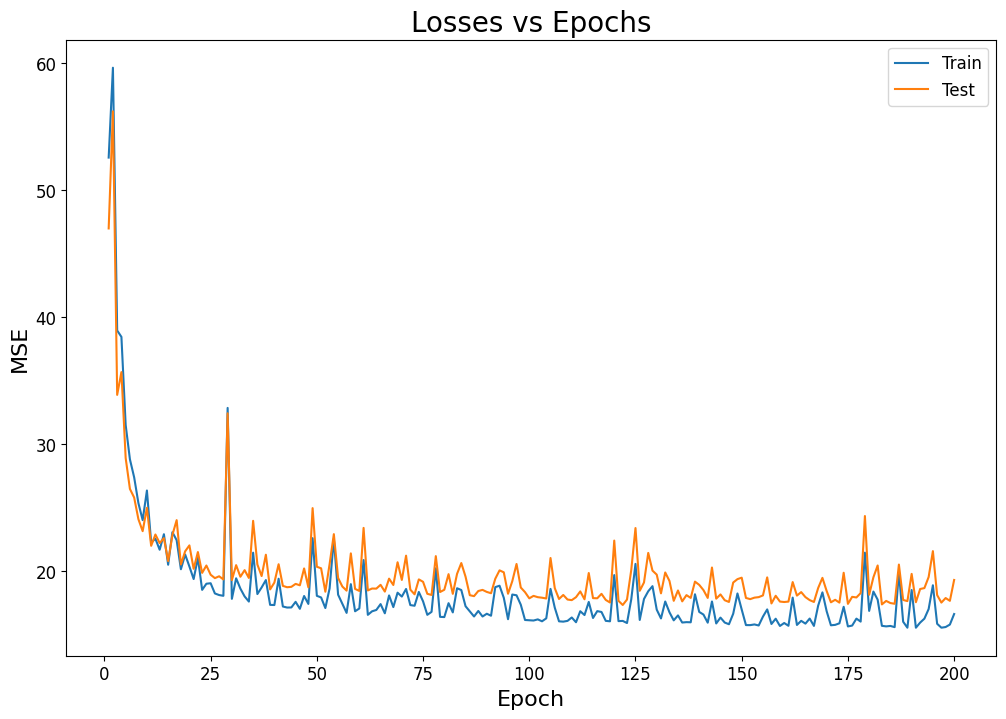

In [26]:
# plot training progress
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(1,201),losses_train, label="Train")
ax.plot(np.arange(1,201),losses_test, label="Test")
ax.set(title="Losses vs Epochs", xlabel = "Epoch", ylabel = "MSE")
ax.legend()
plt.show()

In [27]:
# compile architecture of MLP
mlp = MLP(seed=2)
mlp.add_layer(X_train.shape[1], 100)  ## <-- SOLUTION.
mlp.add_layer(100, 200, "relu")
mlp.add_layer(200, 300, "relu")
mlp.add_layer(300, 100, "relu")
mlp.add_layer(100, 2, "relu")  ## <-- SOLUTION.
print("Number of layers (including input and output layer):", mlp.n_layers())
print("Number of trainable parameters:", mlp.n_parameters())

# train MLP using SGD
mlp, losses_train, losses_test = sgd(
    X_train,
    runway_train,
    X_test,
    runway_test,
    mlp,
    lam=0,
    learning_rate=5e-5,
    n_epochs=200,
    minibatchsize=16,
)

Number of layers (including input and output layer): 6
Number of trainable parameters: 111502


train_loss: 16.49, test_loss: 19.18, train_R^2: 0.81 test_R^2: 0.76 : 100%|██████████| 200/200 [01:15<00:00,  2.64it/s]


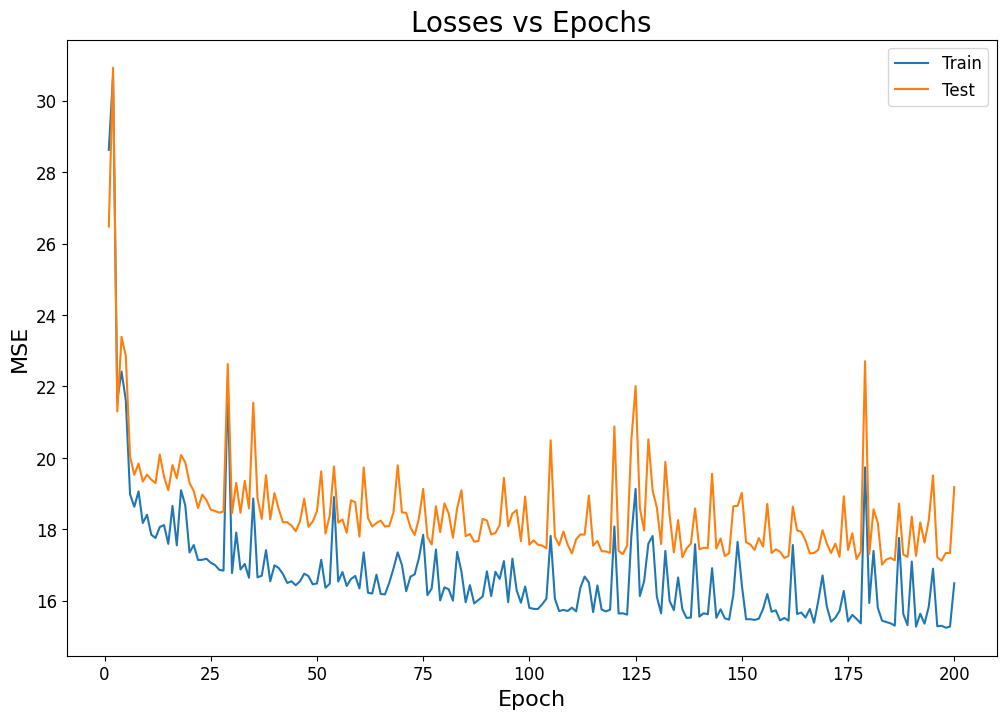

In [28]:
# plot training progress
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(1, 201), losses_train, label="Train")
ax.plot(np.arange(1, 201), losses_test, label="Test")
ax.set(title="Losses vs Epochs", xlabel="Epoch", ylabel="MSE")
ax.legend()
plt.show()

Dropout MLP:
  Number of layers (including input and output): 6
  Number of trainable parameters: 111502


train_loss: 16.93, test_loss: 19.73, train_R^2: 0.80, test_R^2: 0.75: 100%|██████████| 200/200 [01:10<00:00,  2.83it/s]  


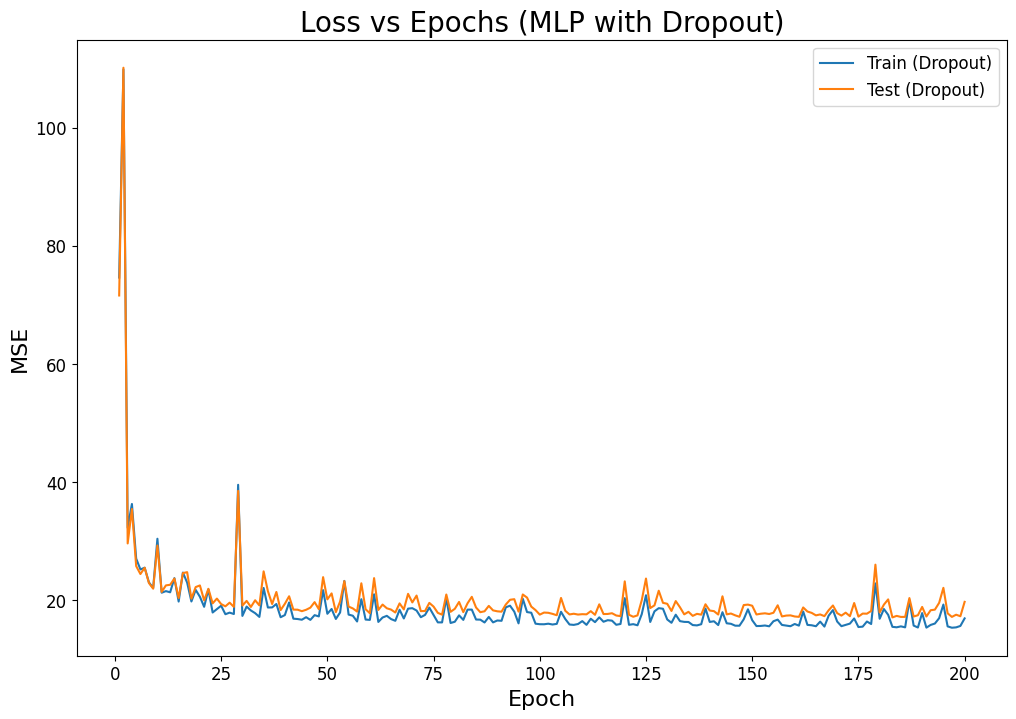

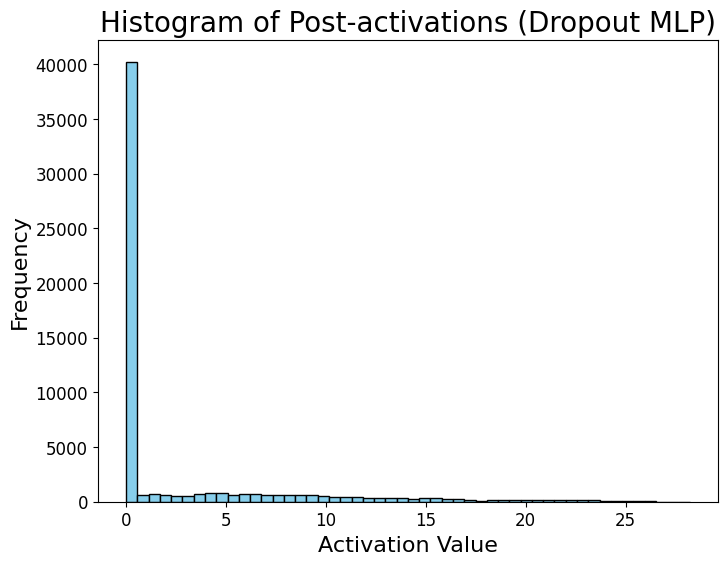

Non-dropout MLP:
  Number of layers (including input and output): 6
  Number of trainable parameters: 111502


train_loss: 16.49, test_loss: 19.18, train_R^2: 0.81, test_R^2: 0.76: 100%|██████████| 200/200 [01:22<00:00,  2.44it/s]


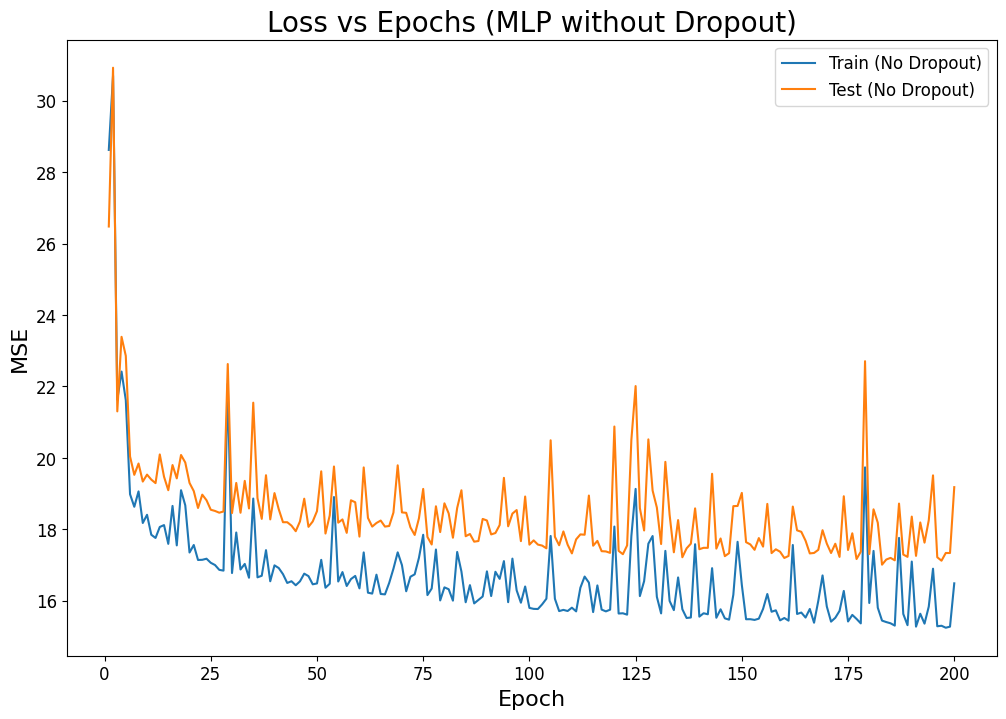

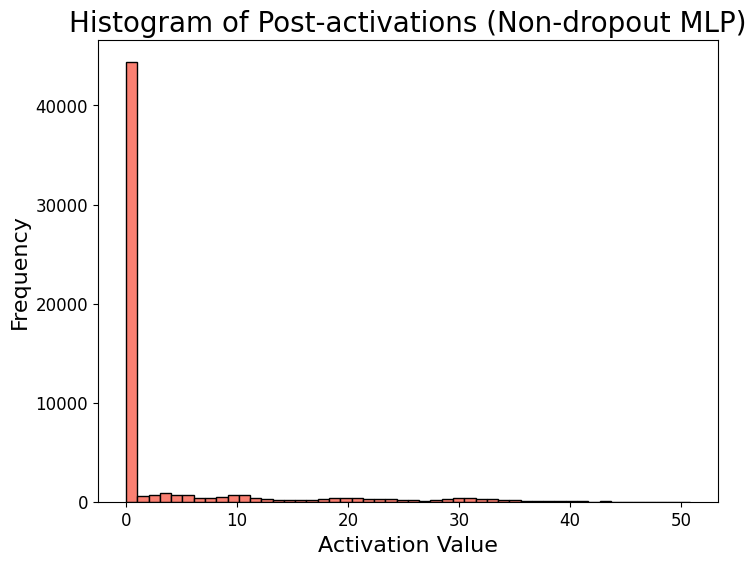

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from collections import defaultdict
from tqdm import tqdm

# Global matplotlib configuration for readability.
SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20
plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

# For reproducibility.
rng = np.random.default_rng(0)

# Load your datasets.
airfield_stats_test = pd.read_csv("airfield_statistics_test.csv")
airfield_stats_train = pd.read_csv("airfield_statistics_train.csv")

X_train_origin = airfield_stats_train.iloc[:, :6].values
y_train_origin = airfield_stats_train.iloc[:, 6].values
X_train = X_train_origin.copy()
y_train = y_train_origin.copy()

X_test_origin = airfield_stats_test.iloc[:, :6].values
y_test_origin = airfield_stats_test.iloc[:, 6].values
X_test = X_test_origin.copy()
y_test = y_test_origin.copy()

cat_columns_dict = {i: False for i in range(X_train.shape[1])}
feature_names = airfield_stats_train.columns[:6].tolist()


def dense(X, W, b):
    a = np.vstack([W @ x + b for x in X])
    return a


def relu_activation(a):
    h = np.maximum(a, 0.0)
    return h


def grad_relu_activation(a):
    grad = np.zeros_like(a)
    grad[a > 0] = 1
    return grad


def random_boolean_array(n, m):
    arr = np.array([False] * n + [True] * (m - n))
    np.random.shuffle(arr)
    return arr


activation_table = {"relu": relu_activation, "identity": lambda x: x}
grad_activation_table = {
    "relu": grad_relu_activation,
    "identity": lambda x: np.ones_like(x),
}


class MLP:
    def __init__(self, seed=42):
        self.layers = []
        self.rng = np.random.default_rng(seed)

    def n_parameters(self):
        return sum(l["b"].size + l["W"].size for l in self.layers)

    def n_layers(self):
        return len(self.layers) + 1 if len(self.layers) > 0 else 0

    def layer_dim(self, index):
        return self.layers[index]["W"].shape

    def add_layer(self, in_dim, out_dim, activation="identity"):
        if self.n_layers() > 0:
            last_out_dim, _ = self.layer_dim(-1)
            assert (
                in_dim == last_out_dim
            ), f"Input-dimension {in_dim} does not match output-dimension {last_out_dim}."
        if self.n_layers() == 0:
            assert activation == "identity", "Input layer must use identity activation."
        self.layers.append(
            {
                "index": len(self.layers),
                "W": self.rng.normal(size=(out_dim, in_dim))
                * np.sqrt(2.0 / (in_dim + out_dim)),
                "b": np.zeros(out_dim),
                "activation": activation,
            }
        )

    def add_layer_dropout(self, in_dim, out_dim, dropout_value, activation="identity"):
        if self.n_layers() > 0:
            last_out_dim, _ = self.layer_dim(-1)
            assert (
                in_dim == last_out_dim
            ), f"Input-dimension {in_dim} does not match output-dimension {last_out_dim}."
        # Create a dropout mask for the weights.
        real_layer = random_boolean_array(int(in_dim * (1 - dropout_value)), in_dim)
        W_origin = self.rng.normal(size=(out_dim, in_dim)) * np.sqrt(
            2.0 / (in_dim + out_dim)
        )
        for i in range(out_dim):
            W_origin[i, :] = W_origin[i, :] * real_layer
        if self.n_layers() == 0:
            assert activation == "identity", "Input layer must use identity activation."
        self.layers.append(
            {
                "index": len(self.layers),
                "W": W_origin,
                "b": np.zeros(out_dim),
                "activation": activation,
            }
        )

    def predict(self, X):
        if X.ndim == 1:
            X = X.reshape(1, -1)
        forward_pass = [{"index": 0, "a": X, "h": X}]
        for k in range(1, len(self.layers)):
            a = dense(
                forward_pass[k - 1]["h"],
                self.layers[k - 1]["W"],
                self.layers[k - 1]["b"],
            )
            activation = activation_table[self.layers[k]["activation"]]
            forward_pass.append({"index": k, "a": a, "h": activation(a)})
        y_hat = dense(forward_pass[-1]["h"], self.layers[-1]["W"], self.layers[-1]["b"])
        return y_hat, forward_pass


def mse_loss(y_true, y_pred):
    y_true = y_true.reshape(y_pred.shape)
    loss = np.mean((y_true - y_pred) ** 2, keepdims=True)
    return loss


def compound_loss(T, T_pred, l=0):
    assert T.size == T_pred.size, "Error"
    T = T.reshape(T_pred.shape)
    T_min, T_max = T[:, 0], T[:, 1]
    T_min_pred, T_max_pred = T_pred[:, 0], T_pred[:, 1]
    T_min = T_min.reshape(T_min_pred.shape)
    T_max = T_max.reshape(T_max_pred.shape)
    MSE_min = mse_loss(T_min, T_min_pred)
    MSE_max = mse_loss(T_max, T_max_pred)
    key = [T_min_pred > T_max_pred]
    return MSE_min + MSE_max + l * np.mean(key)


def compound_grad(T, T_pred, l=0):
    assert T.shape == T_pred.shape, "Error: Shapes of T and T_pred must match!"
    T_min, T_max = T[:, 0], T[:, 1]
    T_min_pred, T_max_pred = T_pred[:, 0], T_pred[:, 1]
    N = T_min.size
    grad_min = (2.0 * (-T_min + T_min_pred) / N).reshape(-1, 1)
    grad_max = (2.0 * (-T_max + T_max_pred) / N).reshape(-1, 1)
    key = (T_min_pred > T_max_pred).astype(float).reshape(-1, 1)
    grad_min += (l * key) / N
    grad_max -= (l * key) / N
    return np.hstack((grad_min, grad_max))


def backpropagate(layers, forward_pass, delta_output):
    gradients = []
    delta = delta_output
    assert len(layers) == len(forward_pass), "Number of layers mismatch."
    for layer, forward_computes in reversed(list(zip(layers, forward_pass))):
        assert forward_computes["index"] == layer["index"], "Index mismatch."
        h = forward_computes["h"]
        gradients.append({"W": (delta.T @ h) / h.shape[0], "b": delta.mean(axis=0)})
        grad_activation_f = grad_activation_table[layer["activation"]]
        grad_activation = grad_activation_f(forward_computes["a"])
        delta = np.stack(
            [
                np.diag(gi) @ layer["W"].T @ di
                for (gi, di) in zip(grad_activation, delta)
            ]
        )
    gradients = list(reversed(gradients))
    return gradients


def sgd_step(X, y, mlp, lam=0, learning_rate=1e-3):
    y_hat, forward_pass = mlp.predict(X)
    delta_output = compound_grad(y, y_hat, lam)
    gradients = backpropagate(mlp.layers, forward_pass, delta_output)
    updated_layers = []
    for layer, grad in zip(mlp.layers, gradients):
        W = layer["W"] - learning_rate * grad["W"]
        b = layer["b"] - learning_rate * grad["b"]
        updated_layers.append(
            {"W": W, "b": b, "activation": layer["activation"], "index": layer["index"]}
        )
    return updated_layers


def r2_score(y, y_hat):
    y = y.reshape(y_hat.shape)
    y_bar = y.mean()
    ss_tot = ((y - y_bar) ** 2).sum()
    ss_res = ((y - y_hat) ** 2).sum()
    return 1 - (ss_res / ss_tot)


def sgd(
    X_train,
    y_train,
    X_test,
    y_test,
    mlp,
    lam=0,
    learning_rate=1e-3,
    n_epochs=10,
    minibatchsize=1,
    seed=42,
):
    rng = np.random.default_rng(seed)
    n_iterations = int(len(y_train) / minibatchsize)
    losses_train = []
    losses_test = []
    epochs_bar = tqdm(range(n_epochs), desc="Epochs")
    for i in epochs_bar:
        p = rng.permutation(len(y_train))
        X_train_shuffled = X_train[p]
        y_train_shuffled = y_train[p]
        for j in range(n_iterations):
            X_batch = X_train_shuffled[j * minibatchsize : (j + 1) * minibatchsize]
            y_batch = y_train_shuffled[j * minibatchsize : (j + 1) * minibatchsize]
            updated_layers = sgd_step(X_batch, y_batch, mlp, lam, learning_rate)
            mlp.layers = updated_layers
        y_hat_train, _ = mlp.predict(X_train)
        losses_train.append(compound_loss(y_train, y_hat_train, l=lam).squeeze())
        y_hat_test, _ = mlp.predict(X_test)
        losses_test.append(compound_loss(y_test, y_hat_test, l=lam).squeeze())
        epochs_bar.set_description(
            f"train_loss: {losses_train[-1]:.2f}, "
            f"test_loss: {losses_test[-1]:.2f}, "
            f"train_R^2: {r2_score(y_train, y_hat_train):.2f}, "
            f"test_R^2: {r2_score(y_test, y_hat_test):.2f}"
        )
    return mlp, losses_train, losses_test


# Prepare the target arrays.
runway_train = np.array(airfield_stats_train.iloc[:, 7:9].values)
runway_test = np.array(airfield_stats_test.iloc[:, 7:9].values)

##############################
# 1. MLP with dropout
##############################
mlp_dropout = MLP(seed=2)
mlp_dropout.add_layer(X_train.shape[1], 100)
mlp_dropout.add_layer(100, 200, "relu")
mlp_dropout.add_layer(200, 300, "relu")
mlp_dropout.add_layer_dropout(300, 100, 0.1, "relu")
mlp_dropout.add_layer(100, 2, "relu")

print("Dropout MLP:")
print("  Number of layers (including input and output):", mlp_dropout.n_layers())
print("  Number of trainable parameters:", mlp_dropout.n_parameters())

mlp_dropout, losses_train_dropout, losses_test_dropout = sgd(
    X_train,
    runway_train,
    X_test,
    runway_test,
    mlp_dropout,
    lam=0,
    learning_rate=5e-5,
    n_epochs=200,
    minibatchsize=16,
)

# Plot loss curves for dropout model.
epochs = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(epochs, losses_train_dropout, label="Train (Dropout)")
ax.plot(epochs, losses_test_dropout, label="Test (Dropout)")
ax.set(title="Loss vs Epochs (MLP with Dropout)", xlabel="Epoch", ylabel="MSE")
ax.legend()
plt.show()

# Get the post-activations of the last hidden layer from the dropout model.
# (Assuming that forward_pass[-1]["h"] corresponds to the post-activations of the 4th hidden layer.)
_, forward_pass_dropout = mlp_dropout.predict(X_train)
post_activations_dropout = forward_pass_dropout[-1]["h"].flatten()

plt.figure(figsize=(8, 6))
plt.hist(post_activations_dropout, bins=50, color="skyblue", edgecolor="black")
plt.title("Histogram of Post-activations (Dropout MLP)")
plt.xlabel("Activation Value")
plt.ylabel("Frequency")
plt.show()

##############################
# 2. MLP without dropout
##############################
mlp_no_dropout = MLP(seed=2)
mlp_no_dropout.add_layer(X_train.shape[1], 100)
mlp_no_dropout.add_layer(100, 200, "relu")
mlp_no_dropout.add_layer(200, 300, "relu")
mlp_no_dropout.add_layer(300, 100, "relu")
mlp_no_dropout.add_layer(100, 2, "relu")

print("Non-dropout MLP:")
print("  Number of layers (including input and output):", mlp_no_dropout.n_layers())
print("  Number of trainable parameters:", mlp_no_dropout.n_parameters())

mlp_no_dropout, losses_train_no_dropout, losses_test_no_dropout = sgd(
    X_train,
    runway_train,
    X_test,
    runway_test,
    mlp_no_dropout,
    lam=0,
    learning_rate=5e-5,
    n_epochs=200,
    minibatchsize=16,
)

# Plot loss curves for non-dropout model.
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(epochs, losses_train_no_dropout, label="Train (No Dropout)")
ax.plot(epochs, losses_test_no_dropout, label="Test (No Dropout)")
ax.set(title="Loss vs Epochs (MLP without Dropout)", xlabel="Epoch", ylabel="MSE")
ax.legend()
plt.show()

# Get the post-activations of the last hidden layer from the non-dropout model.
_, forward_pass_no_dropout = mlp_no_dropout.predict(X_train)
post_activations_no_dropout = forward_pass_no_dropout[-1]["h"].flatten()

plt.figure(figsize=(8, 6))
plt.hist(post_activations_no_dropout, bins=50, color="salmon", edgecolor="black")
plt.title("Histogram of Post-activations (Non-dropout MLP)")
plt.xlabel("Activation Value")
plt.ylabel("Frequency")
plt.show()